<a href="https://colab.research.google.com/github/eliyabriand/Machine-Learning-project-TAU/blob/main/Group_60_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 60 פרויקט סוף קורס- קבוצה

מגישות:
אליה בריאנד (214424160)
ושלי בלנקה (213219462)


**חלק א׳**

In [ ]:
# ==============================================================================
# PART A - Exploratory Data Analysis (EDA)
# This section performs initial data cleaning, explores the dataset through
# visualizations, applies conditional imputation based on the findings,
# and validates the completed dataset.
# ==============================================================================

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    RocCurveDisplay,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

import sys
import warnings

if not sys.warnoptions:
    warnings.simplefilter("ignore")

In [ ]:
df=pd.read_csv("/content/Train_Data.csv")
df_clean = df.copy()

# Load the original training dataset and create a working copy.
# The original dataframe is preserved throughout the notebook.

print("Data Shape:", df_clean.shape)
display(df_clean.head(10))
display(df_clean.describe())

Data Shape: (63464, 29)


,Client_ID,Professionals_Count,Students_Count,Observers_Count,Course_Start_Date,Practical_Hours,Theory_Hours,Registration_Days_Before,Origin_Country,Catering_Package,...,Enrollment_Type,Lanyard_Color,Client_Category,Submission_Source,Returning_Client,Agent_ID,Company_ID,Payment_Terms,Daily_Tuition_Cost,Dropped_Course
0,13766,2,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
1,78660,1,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
2,51396,1,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Red,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
3,34000,2,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Red,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
4,69025,1,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Orange,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,80.0,0
5,46186,2,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,NaN,Red,Tr!aditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
6,20136,2,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
7,17264,2,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admission,Green,Traditional IT & Telecomm,Unknown,0,219.0,NaN,Pay Upon Start,101.5,1
8,49047,2,0.0,0,7/1/2015,0,2,257.0,PRT,Lunch Included,...,General Admissi*on,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0
9,50188,2,0.0,0,7/1/2015,0,2,257.0,prt,Lunch Included,...,General Admission,Blue,Traditional IT & Telecomm,B2B Platforms & Resellers,0,219.0,NaN,Pay Upon Start,101.5,0


,Client_ID,Professionals_Count,Students_Count,Observers_Count,Practical_Hours,Theory_Hours,Registration_Days_Before,Prev_Course_Dropouts,Prev_Course_Attended,Pre_Course_Supports_Tickets,Physical_Course_Kits,Waiting_List_Days,Registration_Changes,Returning_Client,Agent_ID,Company_ID,Daily_Tuition_Cost,Dropped_Course
count,63464.000000,63464.000000,63460.000000,63464.000000,63464.000000,63464.000000,60798.000000,63464.000000,63464.000000,63464.000000,62424.000000,63464.000000,63464.000000,63464.000000,52291.000000,3120.000000,63385.000000,63464.000000
mean,39761.752616,1.835214,8.751718,0.005326,6.609054,2.164392,102.894470,0.095991,0.122967,0.513330,0.026224,3.983676,0.180039,0.027133,197.834752,5119.021474,98.847963,0.414392
std,22878.980699,0.508607,294.238584,0.089662,215.502929,1.469854,109.178824,0.448526,1.535201,0.763563,0.160202,23.195495,0.592577,0.162474,47.393068,70.106299,41.855391,0.492621
min,1.000000,0.000000,0.000000,0.000000,-5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,5002.000000,0.000000,0.000000
25%,19959.750000,2.000000,0.000000,0.000000,0.000000,1.000000,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,184.000000,5035.000000,75.000000,0.000000
50%,39819.500000,2.000000,0.000000,0.000000,1.000000,2.000000,65.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,184.000000,5146.000000,94.500000,0.000000
75%,59570.250000,2.000000,0.000000,0.000000,1.000000,3.000000,150.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,218.000000,5181.000000,117.000000,1.000000
max,79330.000000,4.000000,9999.000000,10.000000,10000.000000,41.000000,629.000000,21.000000,61.000000,5.000000,3.000000,391.000000,21.000000,1.000000,322.000000,5206.000000,5400.000000,1.000000


In [ ]:
# Split the original training data into an internal training set
# and a holdout set (20%) used only for final evaluation.

train_data, test_data = train_test_split(df_clean, test_size=0.2, random_state=42, stratify=df_clean['Dropped_Course']
)
print(f"The Train Data shape is {train_data.shape}")
print(f"The Test Data shape is {test_data.shape}")

The Train Data shape is (50771, 29)
The Test Data shape is (12693, 29)


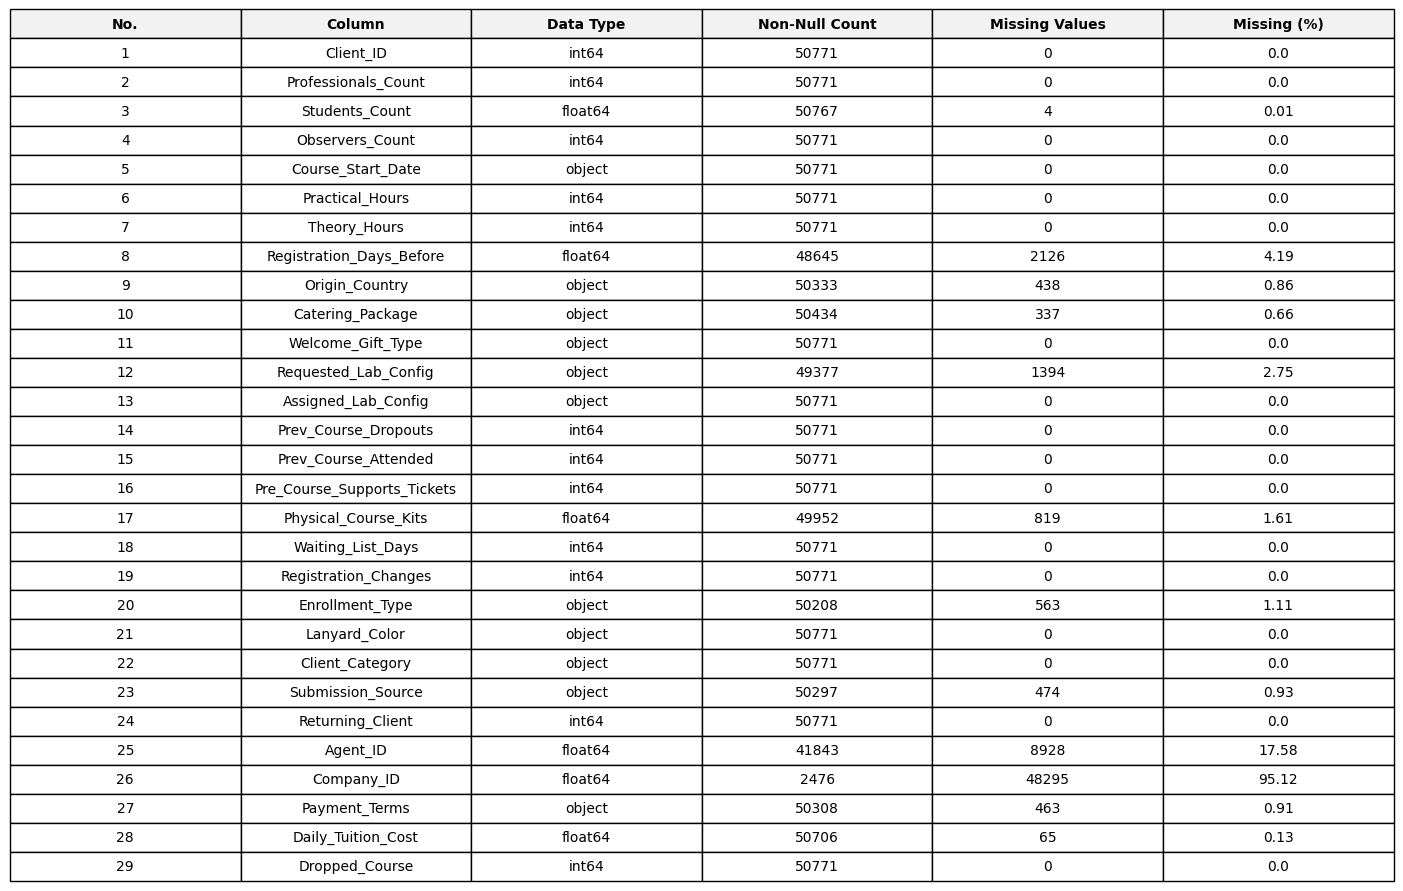

In [ ]:
# Missing Values Summary Table
# Create a summary table describing each column:
# - Data type
# - Number of non-missing values
# - Number of missing values
# - Percentage of missing values

missing_summary = pd.DataFrame({
    "Column": train_data.columns,
    "Data Type": train_data.dtypes.astype(str),
    "Non-Null Count": train_data.notnull().sum().values,
    "Missing Values": train_data.isnull().sum().values,
})

missing_summary["Missing (%)"] = (
    missing_summary["Missing Values"] / len(train_data) * 100
).round(2)

# Add serial numbers
missing_summary.insert(0, "No.", range(1, len(missing_summary) + 1))

# Plot the table

fig, ax = plt.subplots(figsize=(14, 9))
ax.axis("off")

table = ax.table(
    cellText=missing_summary.values,
    colLabels=missing_summary.columns,
    loc="center",
    cellLoc="center",
)

# Formatting
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.4)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("black")

    if row == 0:
        cell.set_facecolor("#F2F2F2")
        cell.set_text_props(weight="bold")

plt.tight_layout()
plt.show()

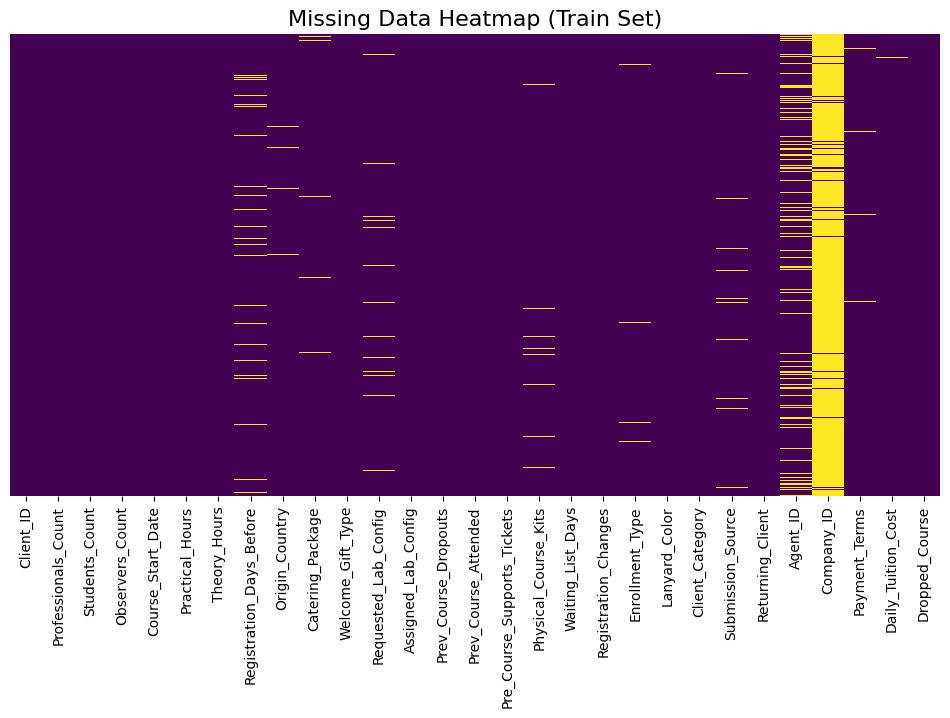

In [ ]:
# Creating Heat Map to show missing data

plt.figure(figsize=(12, 6))
sns.heatmap(train_data.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title('Missing Data Heatmap (Train Set)', fontsize=16)
plt.show()

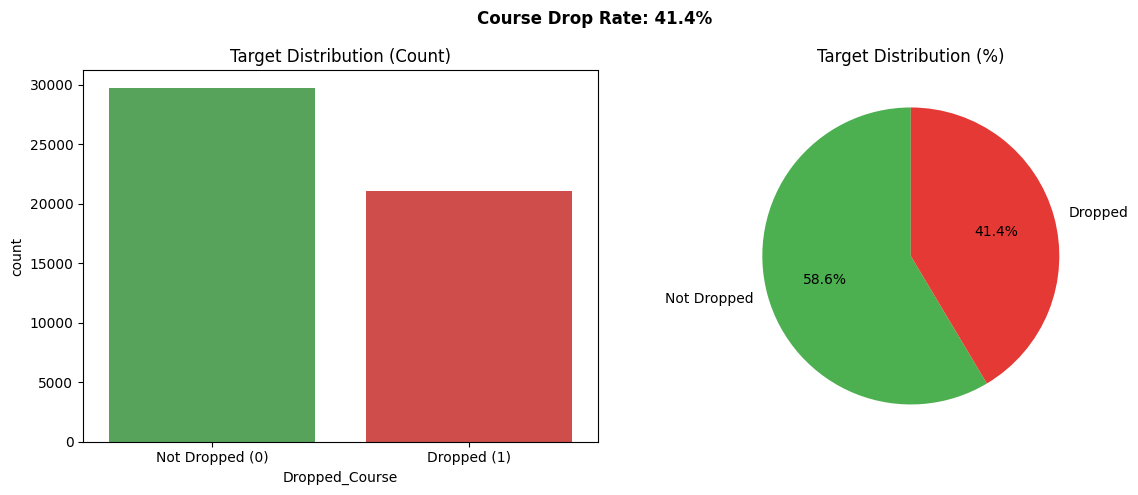

In [ ]:
# Target distribution: check class balance of Dropped_Course before any modeling.
# A ~40/60 split confirms the data is fairly balanced, so accuracy is a meaningful
# baseline metric and no special resampling (class weights) is required.

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=train_data, x='Dropped_Course', hue='Dropped_Course',
              palette=['#4CAF50', '#E53935'], legend=False, ax=ax[0])
ax[0].set_title("Target Distribution (Count)")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['Not Dropped (0)', 'Dropped (1)'])

counts = train_data['Dropped_Course'].value_counts().sort_index()
ax[1].pie(counts, labels=['Not Dropped', 'Dropped'], autopct='%1.1f%%',
          colors=['#4CAF50', '#E53935'], startangle=90)
ax[1].set_title("Target Distribution (%)")

drop_rate = train_data['Dropped_Course'].mean() * 100
plt.suptitle(f"Course Drop Rate: {drop_rate:.1f}%", fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# Base cleaning pipeline applied to train , and reused on test later
# to guarantee identical preprocessing on both sets.

# Key fix: Agent_ID / Company_ID are unique identifiers with no real predictive
# value. Keeping them would let One-Hot Encoding create hundreds of irrelevant
# columns that the model memorizes, inflating dimensionality and AUC. We drop them here.
# Client_ID is kept for now (needed for the final submission file) and removed
# only right before training.
# ==============================================================================

def clean_client_id(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if val_str.endswith('.0'):
        val_str = val_str[:-2]
    cleaned = ''.join(filter(str.isdigit, val_str))
    if cleaned == '':
        return np.nan
    return int(cleaned)

def clean_data_pipeline(df):
    df_clean = df.copy()

    # Clean the client identifier (kept for submission, dropped before training)
    if 'Client_ID' in df_clean.columns:
        df_clean['Client_ID'] = df_clean['Client_ID'].apply(clean_client_id)

    # Parse the date column to datetime
    if 'Course_Start_Date' in df_clean.columns:
        df_clean['Course_Start_Date'] = pd.to_datetime(df_clean['Course_Start_Date'], errors='coerce')

    # Drop high-cardinality identifiers to prevent memorization / dimensionality blow-up
    df_clean.drop(columns=['Agent_ID', 'Company_ID'], errors='ignore', inplace=True)

    # Standardize text in categorical columns (lowercase, strip punctuation/spaces)
    categorical_cols = [
        'Origin_Country', 'Catering_Package', 'Welcome_Gift_Type',
        'Requested_Lab_Config', 'Assigned_Lab_Config', 'Enrollment_Type',
        'Lanyard_Color', 'Client_Category', 'Submission_Source', 'Payment_Terms'
    ]
    for col in categorical_cols:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].str.lower().str.replace(r'[^\w\s]', '', regex=True).str.strip()

    # Fix an impossible value (data-entry error), not a statistical outlier -> set to NaN
    if 'Practical_Hours' in df_clean.columns:
        df_clean.loc[df_clean['Practical_Hours'] > 1000, 'Practical_Hours'] = np.nan

    # Negative values in numeric columns are invalid -> set to NaN for later imputation
    numeric_cols = [
        'Professionals_Count', 'Students_Count', 'Observers_Count','Practical_Hours',
        'Theory_Hours', 'Registration_Days_Before', 'Prev_Course_Dropouts',
        'Prev_Course_Attended', 'Pre_Course_Supports_Tickets',
        'Physical_Course_Kits', 'Waiting_List_Days', 'Registration_Changes',
        'Daily_Tuition_Cost'
    ]
    for col in numeric_cols:
        if col in df_clean.columns:
            df_clean.loc[df_clean[col] < 0, col] = np.nan

    return df_clean

train_data_clean = clean_data_pipeline(train_data)

print(train_data_clean['Enrollment_Type'].value_counts())
print("\nShape after pipeline:", train_data_clean.shape)

Enrollment_Type
general admission             36093
affiliated admission          12098
contractual agreement          1831
organizational arrangement      186
Name: count, dtype: int64

Shape after pipeline: (50771, 27)


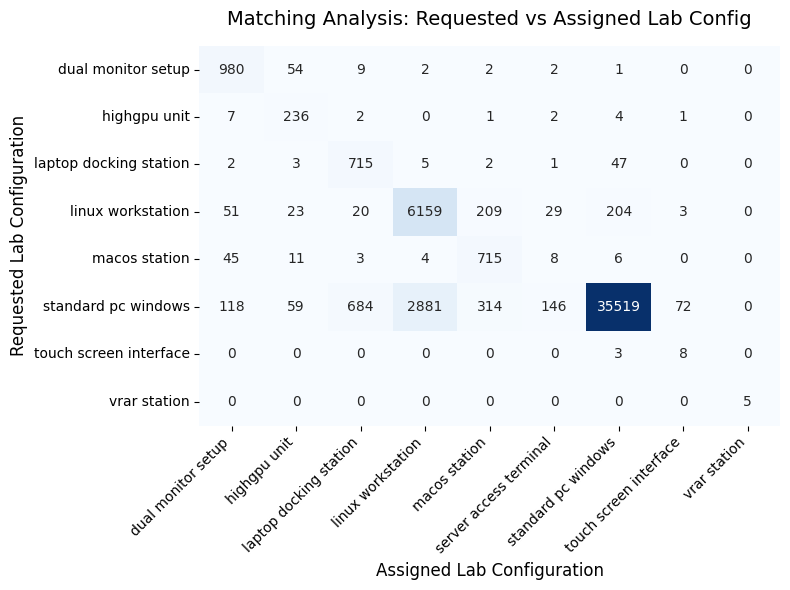

--> Statistical Match Percentage (Diagonal): 89.79%


In [ ]:
# ==============================================================================
# Lab config match analysis: cross-tab of Requested vs Assigned lab environment.
# The diagonal (match %) tells us how often groups got the setup they asked for.
# A very high match rate (~90%) is the rationale for later imputing a missing
# 'Requested' value with the 'Assigned' one - they almost always agree.
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 6))
crosstab_lab = pd.crosstab(train_data_clean['Requested_Lab_Config'], train_data_clean['Assigned_Lab_Config'])

valid_rows = train_data_clean.dropna(subset=['Requested_Lab_Config', 'Assigned_Lab_Config'])
match_pct = (valid_rows['Requested_Lab_Config'] == valid_rows['Assigned_Lab_Config']).mean() * 100

sns.heatmap(crosstab_lab, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Matching Analysis: Requested vs Assigned Lab Config", fontsize=14, pad=15)
ax.set_xlabel("Assigned Lab Configuration", fontsize=12)
ax.set_ylabel("Requested Lab Configuration", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"--> Statistical Match Percentage (Diagonal): {match_pct:.2f}%")

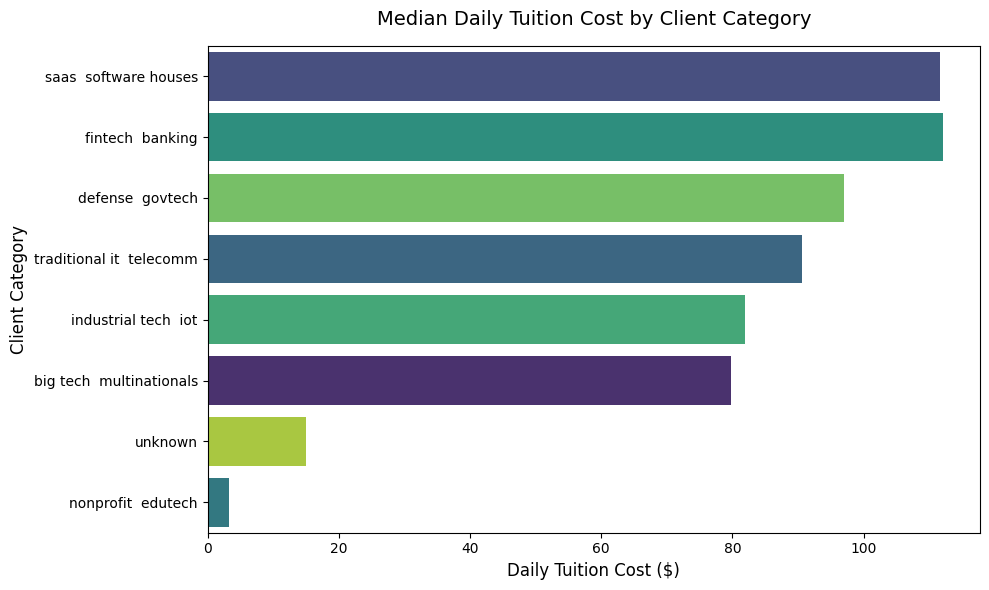

In [ ]:
# ==============================================================================
# Median daily tuition cost per client segment. Shows that price varies
# systematically by segment: the rationale for imputing a missing cost with the
# median of its own segment rather than a single global median.
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 6))
cost_order = train_data_clean.groupby('Client_Category')['Daily_Tuition_Cost'].median().sort_values(ascending=False).index

sns.barplot(data=train_data_clean, x='Daily_Tuition_Cost', y='Client_Category',
            hue='Client_Category', order=cost_order, errorbar=None,
            palette="viridis", legend=False, ax=ax)
ax.set_title("Median Daily Tuition Cost by Client Category", fontsize=14, pad=15)
ax.set_xlabel("Daily Tuition Cost ($)", fontsize=12)
ax.set_ylabel("Client Category", fontsize=12)
plt.tight_layout()
plt.show()

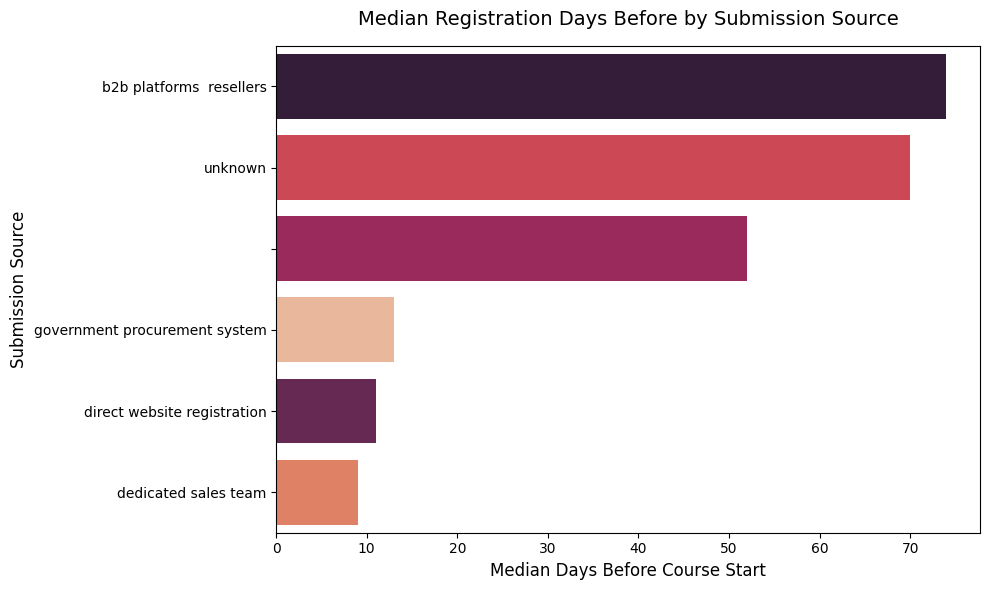

In [ ]:
# ==============================================================================
# Median registration lead-time per submission channel. Different channels show
# clearly different lead times, which justifies imputing missing
# 'Registration_Days_Before' conditionally by channel (group-by imputation).
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 6))
days_order = train_data_clean.groupby('Submission_Source')['Registration_Days_Before'].median().sort_values(ascending=False).index

sns.barplot(data=train_data_clean, x='Registration_Days_Before', y='Submission_Source',
            hue='Submission_Source', order=days_order, estimator=np.nanmedian,
            errorbar=None, palette="rocket", legend=False, ax=ax)
ax.set_title("Median Registration Days Before by Submission Source", fontsize=14, pad=15)
ax.set_xlabel("Median Days Before Course Start", fontsize=12)
ax.set_ylabel("Submission Source", fontsize=12)
plt.tight_layout()
plt.show()

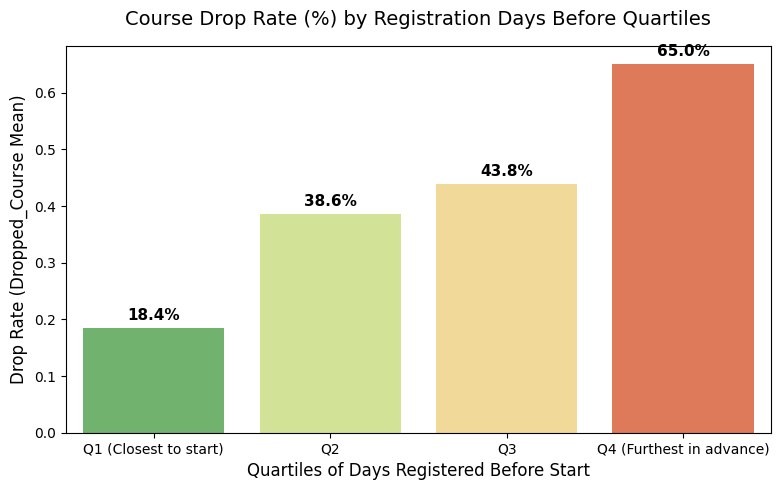

In [ ]:
# ==============================================================================
# Drop rate across quartiles of registration lead-time. Reveals a strong,
# non-linear link between how early a group registers and its drop probability:
# an early signal that lead-time is a high-value predictor.
# NOTE: 'Registration_Days_Q' is a temporary helper for this plot only and is
# dropped at the end so it does not leak in as a duplicate engineered feature.
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 5))
train_data_clean['Registration_Days_Q'] = pd.qcut(
    train_data_clean['Registration_Days_Before'], 4,
    labels=['Q1 (Closest to start)', 'Q2', 'Q3', 'Q4 (Furthest in advance)']
)

sns.barplot(data=train_data_clean, x='Registration_Days_Q', y='Dropped_Course',
            hue='Registration_Days_Q', palette="RdYlGn_r", errorbar=None,
            legend=False, ax=ax)
ax.set_title("Course Drop Rate (%) by Registration Days Before Quartiles", fontsize=14, pad=15)
ax.set_xlabel("Quartiles of Days Registered Before Start", fontsize=12)
ax.set_ylabel("Drop Rate (Dropped_Course Mean)", fontsize=12)

for p in ax.patches:
    ax.annotate(f"{p.get_height()*100:.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points',
                fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# Drop the plot-only helper column so it won't become a duplicate feature later
train_data_clean.drop(columns='Registration_Days_Q', inplace=True)

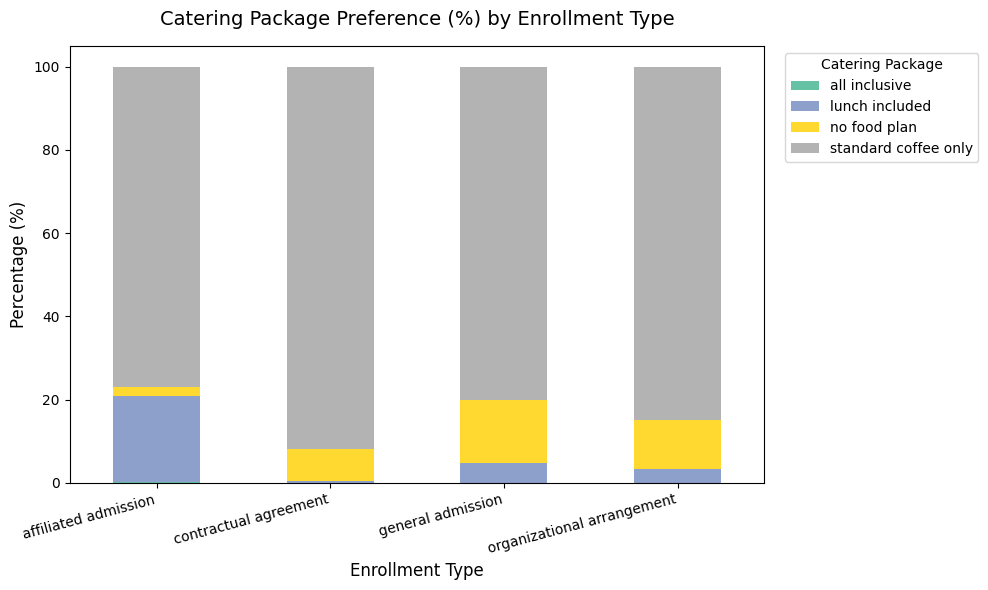

In [ ]:
# ==============================================================================
# Catering preference composition per enrollment type (100%-normalized stacked
# bars). Checks whether enrollment type and catering choice are related, giving
# context on how categorical fields interact before we impute/encode them.
# ==============================================================================

fig, ax = plt.subplots(figsize=(10, 6))
catering_enrollment = pd.crosstab(train_data_clean['Enrollment_Type'], train_data_clean['Catering_Package'], normalize='index') * 100

catering_enrollment.plot(kind='bar', stacked=True, cmap='Set2', ax=ax)
ax.set_title("Catering Package Preference (%) by Enrollment Type", fontsize=14, pad=15)
ax.set_xlabel("Enrollment Type", fontsize=12)
ax.set_ylabel("Percentage (%)", fontsize=12)
ax.legend(title="Catering Package", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

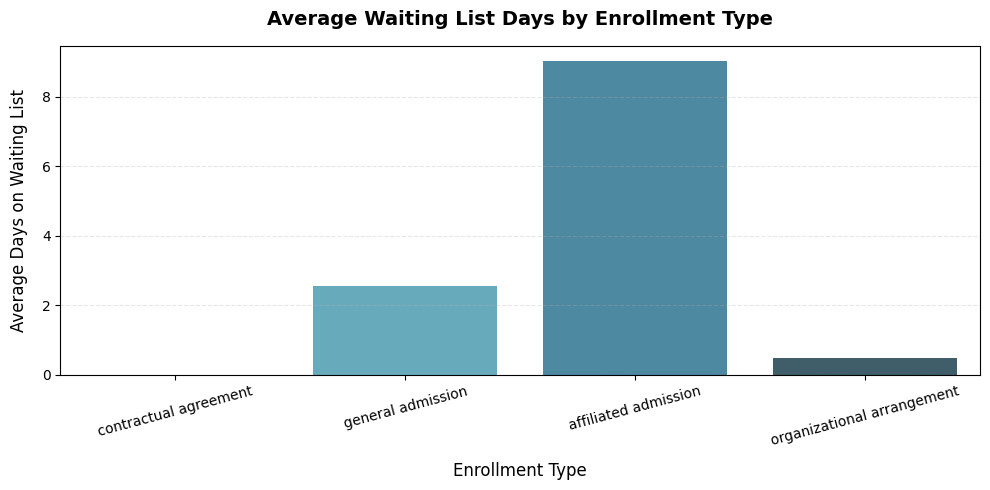

In [ ]:
# ==============================================================================
# Average waiting-list days per enrollment type. Some enrollment types have ~0
# waiting days while others wait much longer - this systematic gap is the basis
# for imputing missing 'Enrollment_Type' conditionally on waiting-time tiers.
# ==============================================================================

plt.figure(figsize=(10, 5))
sns.barplot(data=train_data_clean, x='Enrollment_Type', y='Waiting_List_Days',
            hue='Enrollment_Type', palette='GnBu_d', legend=False, errorbar=None)
plt.title("Average Waiting List Days by Enrollment Type", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Enrollment Type", fontsize=12, labelpad=10)
plt.ylabel("Average Days on Waiting List", fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

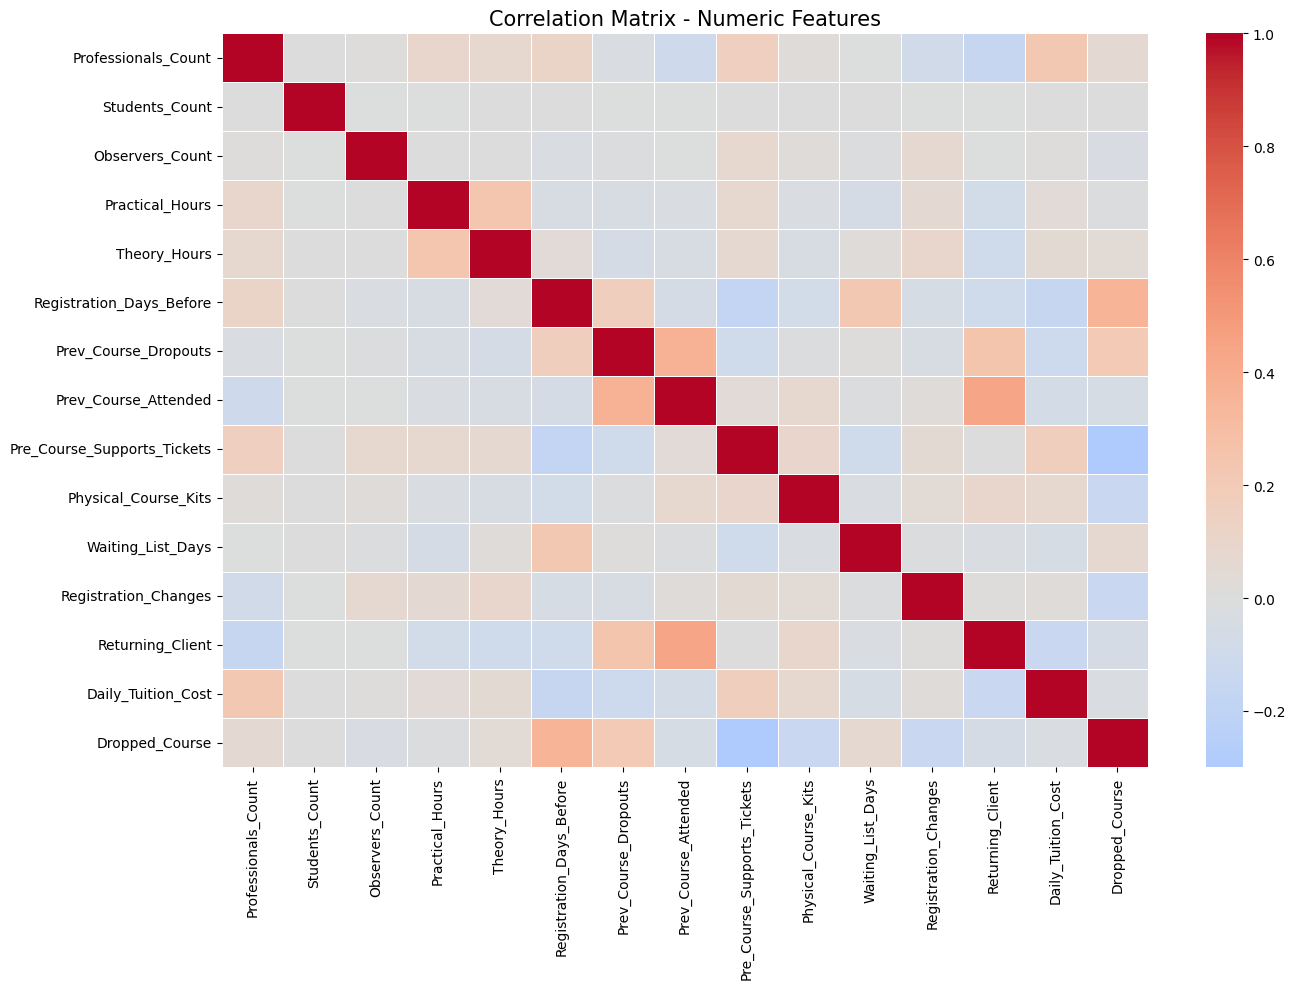

Correlation of numeric features with Dropped_Course:
Registration_Days_Before       0.351319
Pre_Course_Supports_Tickets   -0.299710
Prev_Course_Dropouts           0.203728
Registration_Changes          -0.147032
Physical_Course_Kits          -0.138375
Waiting_List_Days              0.068491
Returning_Client              -0.059163
Professionals_Count            0.055794
Prev_Course_Attended          -0.050010
Theory_Hours                   0.044261
Observers_Count               -0.032204
Daily_Tuition_Cost            -0.024415
Practical_Hours               -0.009949
Students_Count                 0.000219
Name: Dropped_Course, dtype: float64


In [ ]:
# ==============================================================================
# Correlation matrix of numeric features + focused correlation against the target.
# Purpose: (1) spot highly correlated feature pairs (redundancy / multicollinearity)
# and (2) rank which numeric variables move most with Dropped_Course, guiding
# feature engineering and selection later.
# ==============================================================================

plt.figure(figsize=(14, 10))
numeric_for_corr = train_data_clean.select_dtypes(include=['int64', 'float64']).drop(columns=['Client_ID'], errors='ignore')
corr = numeric_for_corr.corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, linewidths=0.5)
plt.title("Correlation Matrix - Numeric Features", fontsize=15)
plt.tight_layout()
plt.show()

# Correlation of each numeric feature with the target, sorted by strength
target_corr = corr['Dropped_Course'].drop('Dropped_Course').sort_values(key=abs, ascending=False)
print("Correlation of numeric features with Dropped_Course:")
print(target_corr)

In [ ]:
# ==============================================================================
# Explicit count of remaining missing values. This is the checklist that tells us
# exactly which columns still need imputation in the next cell
# ==============================================================================
missing_counts = train_data_clean.isnull().sum()
print(missing_counts[missing_counts > 0])

Students_Count                 4
Practical_Hours               94
Registration_Days_Before    2126
Origin_Country               438
Catering_Package             337
Requested_Lab_Config        1394
Physical_Course_Kits         819
Enrollment_Type              563
Submission_Source            474
Payment_Terms                463
Daily_Tuition_Cost            65
dtype: int64


In [ ]:
# ==============================================================================
# Rationale-based imputation. ALL parameters (medians, modes, mappings) are
# computed on TRAIN ONLY and stored in imputation_params, so we can apply the
# exact same values to the test set later -> prevents data leakage and guarantees
# consistent preprocessing across sets.
# ==============================================================================
imputation_params = {}

# 1. Requested lab -> Assigned lab (they match ~90% of the time, per cell 6)
train_data_clean['Requested_Lab_Config'] = train_data_clean['Requested_Lab_Config'].fillna(train_data_clean['Assigned_Lab_Config'])

# 2. Daily tuition cost -> median by client segment (+ global-median fallback)
cost_medians_by_category = train_data_clean.groupby('Client_Category')['Daily_Tuition_Cost'].median()
overall_cost_median = train_data_clean['Daily_Tuition_Cost'].median()
imputation_params['cost_medians_by_category'] = cost_medians_by_category
imputation_params['overall_cost_median'] = overall_cost_median
train_data_clean['Daily_Tuition_Cost'] = (
    train_data_clean['Daily_Tuition_Cost']
    .fillna(train_data_clean['Client_Category'].map(cost_medians_by_category))
    .fillna(overall_cost_median)
)

# 3. Registration lead-time -> median by submission channel (+ global fallback)
days_medians_by_source = train_data_clean.groupby('Submission_Source')['Registration_Days_Before'].median()
overall_days_median = train_data_clean['Registration_Days_Before'].median()
imputation_params['days_medians_by_source'] = days_medians_by_source
imputation_params['overall_days_median'] = overall_days_median
train_data_clean['Registration_Days_Before'] = (
    train_data_clean['Registration_Days_Before']
    .fillna(train_data_clean['Submission_Source'].map(days_medians_by_source))
    .fillna(overall_days_median)
)

# 4. Catering package -> most frequent category (mode)
most_frequent_catering = train_data_clean['Catering_Package'].mode()[0]
imputation_params['most_frequent_catering'] = most_frequent_catering
train_data_clean['Catering_Package'] = train_data_clean['Catering_Package'].fillna(most_frequent_catering)

# 5. Enrollment type -> conditional mode by waiting-time tier (per cell 11)
waiting_bins = [-float('inf'), 0.5, 4, float('inf')]
waiting_labels = ['No_Waiting', 'Short_Waiting', 'Long_Waiting']
train_data_clean['Waiting_Tier_Tmp'] = pd.cut(train_data_clean['Waiting_List_Days'].fillna(0), bins=waiting_bins, labels=waiting_labels)
enrollment_modes_by_tier = train_data_clean.groupby('Waiting_Tier_Tmp', observed=False)['Enrollment_Type'].agg(
    lambda x: x.mode()[0] if not x.mode().empty else 'general admission'
)
overall_enrollment_mode = train_data_clean['Enrollment_Type'].mode()[0]
imputation_params['waiting_bins'] = waiting_bins
imputation_params['enrollment_modes_by_tier'] = enrollment_modes_by_tier
imputation_params['overall_enrollment_mode'] = overall_enrollment_mode
train_data_clean['Enrollment_Type'] = (
    train_data_clean['Enrollment_Type']
    .fillna(train_data_clean['Waiting_Tier_Tmp'].map(enrollment_modes_by_tier))
    .fillna(overall_enrollment_mode)
)
train_data_clean.drop(columns=['Waiting_Tier_Tmp'], inplace=True)

# 6. Remaining columns from cell 12 (previously handled silently - now explicit):
#    Categorical -> explicit "unknown" category. The missingness itself may carry
#    signal, so we flag it instead of forcing the mode.
fill_unknown_cols = ['Origin_Country', 'Submission_Source', 'Payment_Terms']
for col in fill_unknown_cols:
    train_data_clean[col] = train_data_clean[col].fillna('unknown')
imputation_params['fill_unknown_cols'] = fill_unknown_cols

#    Numeric -> median (variables with no clear group-by logic)
numeric_median_cols = ['Physical_Course_Kits', 'Students_Count', 'Practical_Hours']
numeric_medians = {col: train_data_clean[col].median() for col in numeric_median_cols}
imputation_params['numeric_medians'] = numeric_medians
for col, med in numeric_medians.items():
    train_data_clean[col] = train_data_clean[col].fillna(med)

# Final check - should be 0
print("Total missing values after imputation:", train_data_clean.isnull().sum().sum())
print(train_data_clean.isnull().sum()[train_data_clean.isnull().sum() > 0])

Total missing values after imputation: 0
Series([], dtype: int64)


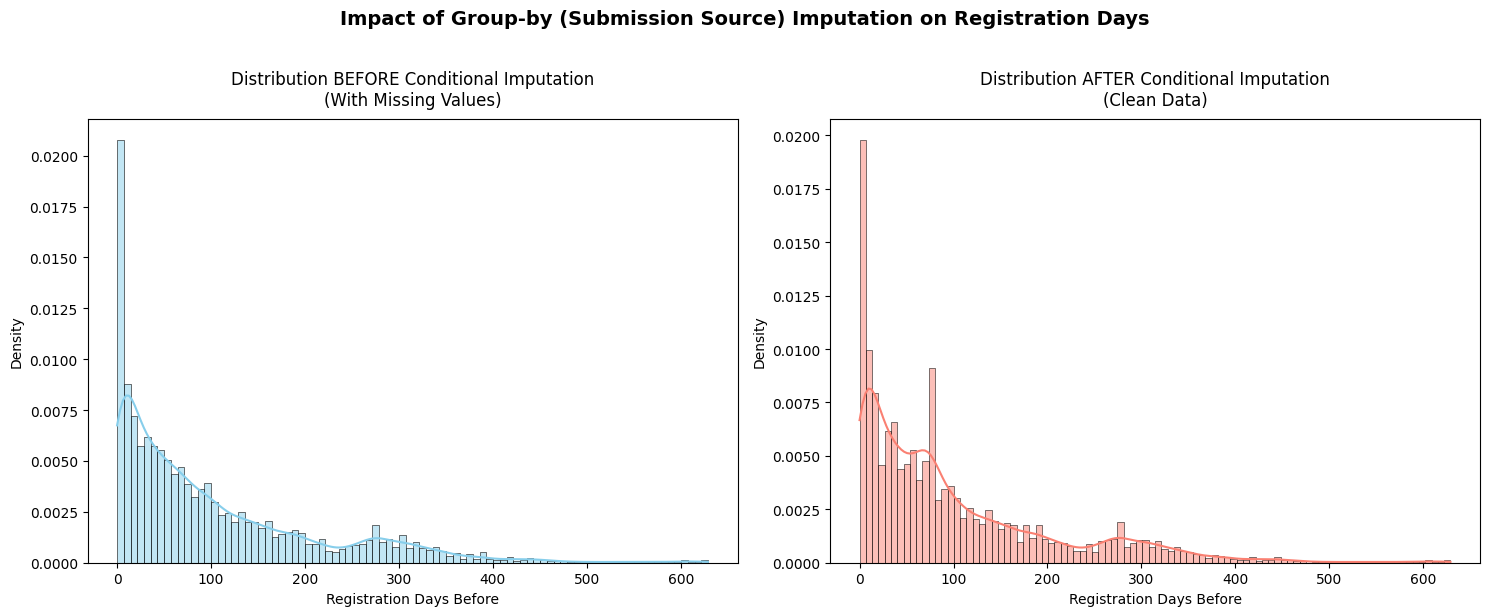

In [ ]:
# ==============================================================================
# Before/after distribution check for Registration_Days_Before. Confirms the
# conditional (by-channel) imputation preserved the original shape and did not
# distort the variable's distribution.
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
sns.histplot(data=train_data, x='Registration_Days_Before', kde=True, color='skyblue', stat='density', ax=axes[0])
axes[0].set_title("Distribution BEFORE Conditional Imputation\n(With Missing Values)", fontsize=12, pad=10)
axes[0].set_xlabel("Registration Days Before"); axes[0].set_ylabel("Density")
sns.histplot(data=train_data_clean, x='Registration_Days_Before', kde=True, color='salmon', stat='density', ax=axes[1])
axes[1].set_title("Distribution AFTER Conditional Imputation\n(Clean Data)", fontsize=12, pad=10)
axes[1].set_xlabel("Registration Days Before"); axes[1].set_ylabel("Density")
plt.suptitle("Impact of Group-by (Submission Source) Imputation on Registration Days", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
group_medians = (
    train_data
    .groupby('Submission_Source')['Registration_Days_Before']
    .median()
)


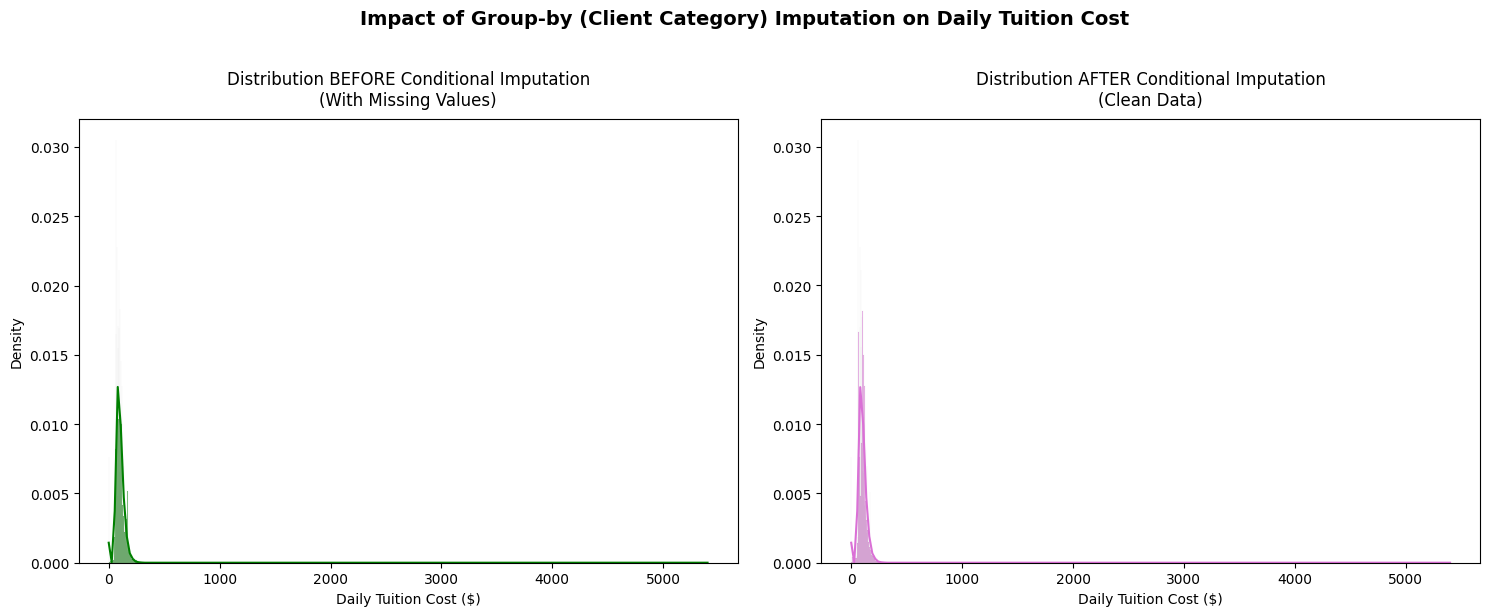

In [ ]:
# ==============================================================================
# Before/after distribution check for Daily_Tuition_Cost. Verifies the by-segment
# median imputation kept the original distribution intact (no artificial spikes).
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
sns.histplot(data=train_data, x='Daily_Tuition_Cost', kde=True, color='green', stat='density', ax=axes[0])
axes[0].set_title("Distribution BEFORE Conditional Imputation\n(With Missing Values)", fontsize=12, pad=10)
axes[0].set_xlabel("Daily Tuition Cost ($)"); axes[0].set_ylabel("Density")
sns.histplot(data=train_data_clean, x='Daily_Tuition_Cost', kde=True, color='orchid', stat='density', ax=axes[1])
axes[1].set_title("Distribution AFTER Conditional Imputation\n(Clean Data)", fontsize=12, pad=10)
axes[1].set_xlabel("Daily Tuition Cost ($)"); axes[1].set_ylabel("Density")
plt.suptitle("Impact of Group-by (Client Category) Imputation on Daily Tuition Cost", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**חלק ב׳**

In [ ]:
### PART B: Feature Engineering and Data Preparation ###

# Create business-oriented features, remove extreme outliers,
# encode categorical variables and scale numeric features.


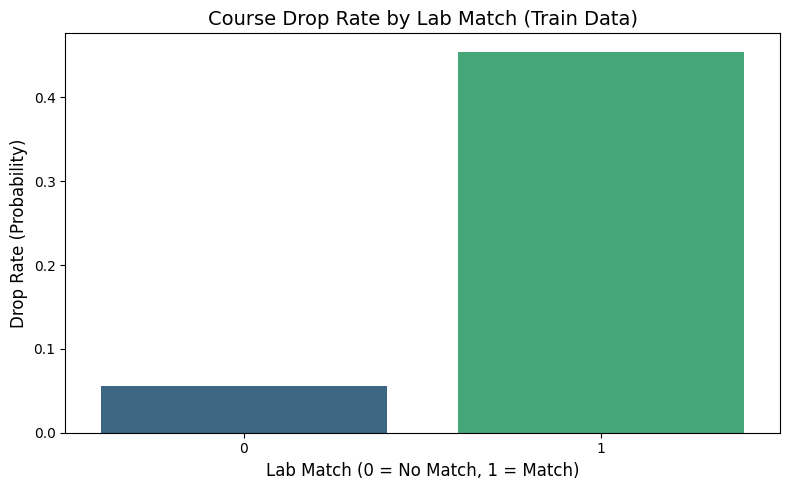

In [ ]:
# ==============================================================================
# Feature Engineering
# ==============================================================================
# Feature 1: Lab_Match — if the group get the lab environment it requested -
# 1 = requested config matches assigned config, 0 = mismatch.

# a mismatch (getting a different setup than asked for) can signal
# dissatisfaction that pushes a group toward dropping. Created on
# train_data_clean so it actually enters the model's feature set.
# ==============================================================================
train_data_clean['Lab_Match'] = (
    train_data_clean['Requested_Lab_Config'] == train_data_clean['Assigned_Lab_Config']
).astype(int)

# Visualize the drop rate for match vs mismatch to validate the feature's signal
plt.figure(figsize=(8, 5))
sns.barplot(x='Lab_Match', y='Dropped_Course', data=train_data_clean,
            hue='Lab_Match', errorbar=None, palette='viridis', legend=False)
plt.title('Course Drop Rate by Lab Match (Train Data)', fontsize=14)
plt.ylabel('Drop Rate (Probability)', fontsize=12)
plt.xlabel('Lab Match (0 = No Match, 1 = Match)', fontsize=12)
plt.xticks([0, 1])
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# Feature engineering (continued)
# ==============================================================================
feature_params = {}

# Feature 2: Registration_Urgency: bucket registration lead-time into 4 quartiles.
# Turns a continuous signal into an interpretable ordinal feature. We store the
# bin edges (with open ends) to apply identical buckets to the test set later.
train_data_clean['Registration_Urgency'], urgency_bins = pd.qcut(
    train_data_clean['Registration_Days_Before'], q=4,
    labels=['Last_Minute', 'Short_Notice', 'Advanced', 'Far_Advanced'],
    retbins=True
)
urgency_bins_safe = urgency_bins.copy()
urgency_bins_safe[0], urgency_bins_safe[-1] = -np.inf, np.inf
feature_params['urgency_bins'] = urgency_bins_safe
feature_params['urgency_labels'] = ['Last_Minute', 'Short_Notice', 'Advanced', 'Far_Advanced']

# Feature 3: Total_Participants: sum of the three attendee types. A single "group
# size" signal lets the model relate order magnitude to drop risk.
train_data_clean['Total_Participants'] = (
    train_data_clean['Professionals_Count']
    + train_data_clean['Students_Count']
    + train_data_clean['Observers_Count']
)

# Feature 4: Start_Month: extract the month from the start date, then drop the raw
# date (XGBoost can't use a datetime). Captures possible seasonality in drops.
if 'Course_Start_Date' in train_data_clean.columns:
    train_data_clean['Start_Month'] = train_data_clean['Course_Start_Date'].dt.month
    train_data_clean.drop(columns=['Course_Start_Date'], inplace=True)

# Total number of previous course outcomes
total_previous_courses = (
    train_data_clean['Prev_Course_Dropouts']
    + train_data_clean['Prev_Course_Attended']
)

# Historical dropout rate:
# dropouts divided by all previous course outcomes
train_data_clean['Historical_Drop_Rate'] = np.where(
    total_previous_courses > 0,
    train_data_clean['Prev_Course_Dropouts'] / total_previous_courses,
    0.0
)
# Feature 6: Practical_Theory_Ratio — practical hours relative to theory hours.
# Captures the *nature* of the course (hands-on vs lecture-heavy) beyond raw hours.
# np.where guards against division by zero (denominator 0 -> treated as 1).
train_data_clean['Practical_Theory_Ratio'] = (
    train_data_clean['Practical_Hours']
    / np.where(train_data_clean['Theory_Hours'] == 0, 1, train_data_clean['Theory_Hours'])
)

# Feature 7: Students_Professionals_Ratio — group composition (students per pro).
# A proxy for the group's profile/commitment level.
train_data_clean['Students_Professionals_Ratio'] = (
    train_data_clean['Students_Count']
    / np.where(train_data_clean['Professionals_Count'] == 0, 1, train_data_clean['Professionals_Count'])
)

# Preview the engineered features
new_features = [
    'Lab_Match', 'Registration_Urgency', 'Total_Participants', 'Start_Month',
    'Historical_Drop_Rate', 'Practical_Theory_Ratio', 'Students_Professionals_Ratio'
]
display(train_data_clean[new_features].head())

,Lab_Match,Registration_Urgency,Total_Participants,Start_Month,Historical_Drop_Rate,Practical_Theory_Ratio,Students_Professionals_Ratio
8022,1,Far_Advanced,2.0,10,1.0,1.0,0.0
4634,1,Advanced,2.0,9,0.0,0.0,0.0
27315,1,Far_Advanced,2.0,5,0.0,2.0,0.0
35761,1,Far_Advanced,2.0,8,0.0,0.0,0.0
7184,1,Far_Advanced,2.0,9,1.0,0.0,0.0


In [ ]:
# One-Hot Encoding of categorical columns + assembling X_train / y_train.

# ==============================================================================
# We fit the encoder on TRAIN only and store it (plus the final column list) so
# the test set can be transformed and aligned identically in Part D.
# One-Hot chosen for transparency: no artificial ordinal relationship is imposed,
# and after dropping the ID columns in Part A the resulting width stays manageable.
# ==============================================================================
categorical_cols = train_data_clean.select_dtypes(include=['object', 'category']).columns.tolist()

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_array = encoder.fit_transform(train_data_clean[categorical_cols])
encoded_cols_names = encoder.get_feature_names_out(categorical_cols)
local_encoded_df = pd.DataFrame(encoded_array, columns=encoded_cols_names, index=train_data_clean.index)

df_for_ml = pd.concat(
    [train_data_clean.drop(columns=categorical_cols, errors='ignore'), local_encoded_df],
    axis=1
)

# Separate target and drop the client identifier (kept only for the submission file)
X_train = df_for_ml.drop(columns=['Dropped_Course'], errors='ignore')
y_train = df_for_ml['Dropped_Course']
X_train.drop(columns=[c for c in ['Client_ID'] if c in X_train.columns], inplace=True, errors='ignore')

# Safety net: median-fill any residual numeric NaNs so scaling won't crash
numeric_cols = X_train.select_dtypes(
    include=['float64', 'int64', 'int32']
).columns
residual_numeric_medians = X_train[numeric_cols].median()
feature_params['residual_numeric_medians'] = (
    residual_numeric_medians
)
X_train[numeric_cols] = X_train[numeric_cols].fillna(
    residual_numeric_medians
)
# Store artifacts for identical test-time processing (Part D)
feature_params['encoder'] = encoder
feature_params['encoded_cols_names'] = encoded_cols_names
feature_params['categorical_cols'] = categorical_cols
feature_params['train_columns'] = X_train.columns.tolist()

print(f"Number of features after encoding: {X_train.shape[1]}")
print(f"X_train shape: {X_train.shape}")

Number of features after encoding: 227
X_train shape: (50771, 227)


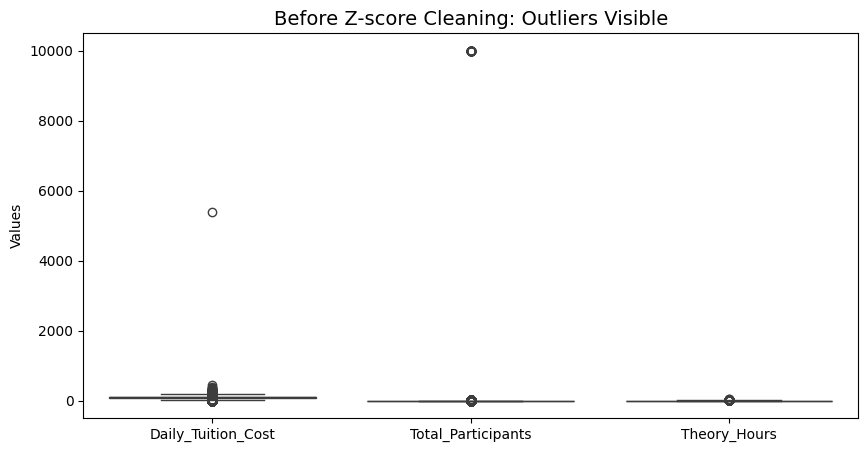

--- Outlier removal summary ---
Original rows: 50771 | After cleaning: 50036
Total removed: 735 rows (1.4%)


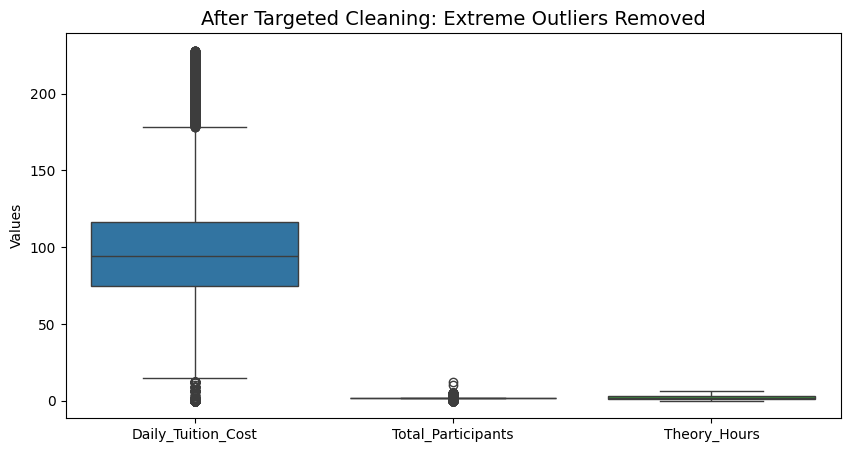

In [ ]:
# Outlier Analysis: targeted Z-score removal (train only; we never drop test rows).

# ==============================================================================
#   - Daily_Tuition_Cost / Theory_Hours: continuous & roughly symmetric -> Z-score
#     (remove rows beyond 3 standard deviations from the mean).
#   - Total_Participants: heavy-tailed count -> a hard, business-driven cap (>500
#     is a data anomaly) rather than a distribution-based rule.
# ==============================================================================
cols_to_check = ['Daily_Tuition_Cost', 'Total_Participants', 'Theory_Hours']
existing_cols = [c for c in cols_to_check if c in X_train.columns]

# Before: show the outliers
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train[existing_cols])
plt.title('Before Z-score Cleaning: Outliers Visible', fontsize=14)
plt.ylabel('Values')
plt.show()

# Z-score filter on the symmetric continuous columns
cols_for_z = ['Daily_Tuition_Cost', 'Theory_Hours']
z_scores = np.abs((X_train[cols_for_z] - X_train[cols_for_z].mean()) / X_train[cols_for_z].std())
valid_z = (z_scores < 3).all(axis=1)

# Targeted hard threshold for participant count
valid_participants = X_train['Total_Participants'] <= 500

# Keep rows valid on both conditions; keep X and y in sync via the shared index
valid_rows = valid_z & valid_participants
X_train_cleaned = X_train[valid_rows].copy()
y_train_cleaned = y_train[valid_rows].copy()

print("--- Outlier removal summary ---")
print(f"Original rows: {len(X_train)} | After cleaning: {len(X_train_cleaned)}")
print(f"Total removed: {len(X_train) - len(X_train_cleaned)} rows "
      f"({(len(X_train) - len(X_train_cleaned)) / len(X_train) * 100:.1f}%)")

# After: show the cleaned distribution
plt.figure(figsize=(10, 5))
sns.boxplot(data=X_train_cleaned[existing_cols])
plt.title('After Targeted Cleaning: Extreme Outliers Removed', fontsize=14)
plt.ylabel('Values')
plt.show()

In [ ]:
# Feature scaling with MinMaxScaler (fit on cleaned train only).

# ==============================================================================
#  Brings every feature to [0, 1] so magnitude-sensitive models (e.g. logistic
# regression) don't over-weight large-valued columns. The fitted scaler is stored
# for identical application to the test set in Part D.
# ==============================================================================
scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_cleaned),
    columns=X_train_cleaned.columns,
    index=X_train_cleaned.index
)
feature_params['scaler'] = scaler

print("Scaling complete.")
display(X_train_scaled.head())

Scaling complete.


,Professionals_Count,Students_Count,Observers_Count,Practical_Hours,Theory_Hours,Registration_Days_Before,Prev_Course_Dropouts,Prev_Course_Attended,Pre_Course_Supports_Tickets,Physical_Course_Kits,...,Submission_Source_unknown,Payment_Terms_,Payment_Terms_pay upon start,Payment_Terms_prepaid nonrefundable,Payment_Terms_refundable deposit,Payment_Terms_unknown,Registration_Urgency_Advanced,Registration_Urgency_Far_Advanced,Registration_Urgency_Last_Minute,Registration_Urgency_Short_Notice
8022,0.5,0.0,0.0,0.25,0.166667,0.561208,0.047619,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4634,0.5,0.0,0.0,0.00,0.333333,0.117647,0.000000,0.0,0.2,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
27315,0.5,0.0,0.0,0.50,0.166667,0.325914,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
35761,0.5,0.0,0.0,0.00,0.666667,0.278219,0.000000,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7184,0.5,0.0,0.0,0.00,0.333333,0.329094,0.047619,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


**חלק ג׳**

In [ ]:
# ==============================================================================
# PART C: Model Training with Hyperparameter Tuning (GridSearchCV)
#
# Train Logistic Regression, Random Forest and XGBoost models.
# Hyperparameters are optimized using GridSearchCV with 3-fold cross-validation.
# The tuned models are stored for evaluation in Part D.
# ==============================================================================


In [ ]:
# ==============================================================================
# We train 3 models and tune each with 3-fold CV, optimizing directly for ROC-AUC
# (the project's grading metric). All searches run on the scaled, outlier-cleaned
# training data. Regularization params are tuned to control the Bias-Variance
# tradeoff and prevent overfitting.
# ==============================================================================
y_train_final = y_train_cleaned  # aligned with the cleaned rows via the shared index
print(f"Final training dimensions: X_train: {X_train_scaled.shape}, y_train: {y_train_final.shape}")

# ------------------------------------------------------------------------------
# Model 1: Logistic Regression: linear baseline. 'C' controls regularization
# strength (smaller C = stronger regularization -> less overfitting).
# ------------------------------------------------------------------------------
print("\n--- Training Model 1: Logistic Regression ---")
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg_param_grid = {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2']}
grid_log_reg = GridSearchCV(log_reg, log_reg_param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_log_reg.fit(X_train_scaled, y_train_final)
print(f"Best params (Logistic Regression): {grid_log_reg.best_params_}")
print(f"Cross-validated AUC: {grid_log_reg.best_score_:.4f}")

# ------------------------------------------------------------------------------
# Model 2: Random Forest: bagging ensemble. 'max_depth' and 'min_samples_split'
# limit tree complexity, the main levers against overfitting here.
# ------------------------------------------------------------------------------
print("\n--- Training Model 2: Random Forest ---")
rf = RandomForestClassifier(random_state=42)
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

grid_rf = GridSearchCV(rf, rf_param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train_final)
print(f"Best params (Random Forest): {grid_rf.best_params_}")
print(f"Cross-validated AUC: {grid_rf.best_score_:.4f}")

# ------------------------------------------------------------------------------
# Model 3: XGBoost: gradient boosting, strong on tabular data. 'learning_rate'
# and 'max_depth' balance Bias-Variance. scale_pos_weight compensates for the
# mild class imbalance (ratio of negatives to positives in train).
# ------------------------------------------------------------------------------
print("\n--- Training Model 3: XGBoost ---")
neg, pos = (y_train_final == 0).sum(), (y_train_final == 1).sum()
scale_pos_weight = neg / pos
print(f"Class balance -> negatives: {neg}, positives: {pos}, scale_pos_weight: {scale_pos_weight:.3f}")

xgb = XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=scale_pos_weight)
xgb_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 6,9],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}
grid_xgb = GridSearchCV(xgb, xgb_param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train_scaled, y_train_final)
print(f"Best params (XGBoost): {grid_xgb.best_params_}")
print(f"Cross-validated AUC: {grid_xgb.best_score_:.4f}")

# ------------------------------------------------------------------------------
# Summary table + automatic selection of the best model by validation AUC.
# The winner is stored for direct, data-driven reuse in Part D (no hard-coding).
# ------------------------------------------------------------------------------
grids = {
    'Logistic Regression': grid_log_reg,
    'Random Forest': grid_rf,
    'XGBoost': grid_xgb
}

results_summary = pd.DataFrame({
    'Model': list(grids.keys()),
    'Best Parameters': [g.best_params_ for g in grids.values()],
    'Validation AUC Score': [g.best_score_ for g in grids.values()]
}).sort_values(by='Validation AUC Score', ascending=False).reset_index(drop=True)

print("\n=== Model performance under cross-validation (Validation AUC) ===")
display(results_summary)


Final training dimensions: X_train: (50036, 227), y_train: (50036,)

--- Training Model 1: Logistic Regression ---
Best params (Logistic Regression): {'C': 10, 'penalty': 'l2'}
Cross-validated AUC: 0.9044

--- Training Model 2: Random Forest ---
Best params (Random Forest): {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Cross-validated AUC: 0.9452

--- Training Model 3: XGBoost ---
Class balance -> negatives: 29374, positives: 20662, scale_pos_weight: 1.422
Best params (XGBoost): {'learning_rate': 0.2, 'max_depth': 9, 'n_estimators': 100, 'subsample': 1.0}
Cross-validated AUC: 0.9483

=== Model performance under cross-validation (Validation AUC) ===


,Model,Best Parameters,Validation AUC Score
0,XGBoost,"{'learning_rate': 0.2, 'max_depth': 9, 'n_esti...",0.948314
1,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.945153
2,Logistic Regression,"{'C': 10, 'penalty': 'l2'}",0.904448


**חלק ד׳**

In [ ]:
# ==============================================================================
# PART D - Model Evaluation
#
# Compare the three trained models on the internal holdout set.
# The selected XGBoost model is then analyzed using SHAP to explain
# both global feature importance and individual predictions.
# ==============================================================================

In [ ]:
# process_new_data
# Applies the complete preprocessing pipeline learned from the training data
# to unseen data:
#   1. Base cleaning
#   2. Imputation using TRAIN-derived parameters
#   3. Feature engineering
#   4. Removal of identifiers and target
#   5. One-Hot Encoding using the fitted TRAIN encoder
#   6. Alignment to the exact TRAIN feature schema
#   7. Residual missing-value completion using TRAIN medians
#   8. Scaling using the fitted TRAIN scaler

def process_new_data(df_raw):
    # Work on a copy so the original dataframe is not modified
    df = clean_data_pipeline(df_raw.copy())

    # Step 1: Imputation using parameters learned from TRAIN only

    # Requested laboratory configuration:
    # use the assigned configuration when the requested one is missing
    df['Requested_Lab_Config'] = (
        df['Requested_Lab_Config']
        .fillna(df['Assigned_Lab_Config'])
    )

    # Daily tuition cost:
    # median by client category, followed by the global train median
    df['Daily_Tuition_Cost'] = (
        df['Daily_Tuition_Cost']
        .fillna(
            df['Client_Category'].map(
                imputation_params['cost_medians_by_category']
            )
        )
        .fillna(imputation_params['overall_cost_median'])
    )

    # Registration lead time:
    # median by submission source, followed by the global train median
    df['Registration_Days_Before'] = (
        df['Registration_Days_Before']
        .fillna(
            df['Submission_Source'].map(
                imputation_params['days_medians_by_source']
            )
        )
        .fillna(imputation_params['overall_days_median'])
    )

    # Catering package:
    # most frequent category from the training data
    df['Catering_Package'] = (
        df['Catering_Package']
        .fillna(imputation_params['most_frequent_catering'])
    )

    # Enrollment type:
    # conditional mode according to waiting-time tier
    waiting_tier = pd.cut(
        df['Waiting_List_Days'].fillna(0),
        bins=imputation_params['waiting_bins'],
        labels=['No_Waiting', 'Short_Waiting', 'Long_Waiting']
    )

    df['Enrollment_Type'] = (
        df['Enrollment_Type']
        .fillna(
            waiting_tier.map(
                imputation_params['enrollment_modes_by_tier']
            )
        )
        .fillna(imputation_params['overall_enrollment_mode'])
    )

    # Remaining categorical columns:
    # preserve missingness as an explicit "unknown" category
    for col in imputation_params['fill_unknown_cols']:
        if col in df.columns:
            df[col] = df[col].fillna('unknown')

    # Remaining numeric columns:
    # use medians learned from the training data
    for col, median_value in imputation_params['numeric_medians'].items():
        if col in df.columns:
            df[col] = df[col].fillna(median_value)

    # Step 2: Feature engineering — identical to the training process

    # Feature 1: whether requested and assigned laboratory configurations match
    df['Lab_Match'] = (
        df['Requested_Lab_Config']
        == df['Assigned_Lab_Config']
    ).astype(int)

    # Feature 2: registration urgency using bin edges learned from TRAIN
    df['Registration_Urgency'] = pd.cut(
        df['Registration_Days_Before'],
        bins=feature_params['urgency_bins'],
        labels=feature_params['urgency_labels'],
        include_lowest=True
    )

    # Feature 3: total number of participants
    df['Total_Participants'] = (
        df['Professionals_Count']
        + df['Students_Count']
        + df['Observers_Count']
    )

    # Feature 4: course starting month
    if 'Course_Start_Date' in df.columns:
        df['Start_Month'] = df['Course_Start_Date'].dt.month
        df.drop(columns=['Course_Start_Date'], inplace=True)

    # Feature 5: historical dropout rate
    # Dropouts divided by all previous course outcomes
    total_previous_courses = (
        df['Prev_Course_Dropouts']
        + df['Prev_Course_Attended']
    )

    df['Historical_Drop_Rate'] = np.where(
        total_previous_courses > 0,
        df['Prev_Course_Dropouts'] / total_previous_courses,
        0.0
    )

    # Feature 6: practical hours relative to theory hours
    df['Practical_Theory_Ratio'] = (
        df['Practical_Hours']
        / np.where(
            df['Theory_Hours'] == 0,
            1,
            df['Theory_Hours']
        )
    )

    # Feature 7: students relative to professionals
    df['Students_Professionals_Ratio'] = (
        df['Students_Count']
        / np.where(
            df['Professionals_Count'] == 0,
            1,
            df['Professionals_Count']
        )
    )

    # Step 3: Remove columns that must not enter the model
    # Client_ID is needed only for the final submission file.
    # Dropped_Course may exist in the internal holdout, but it is the target.
    df.drop(
        columns=['Client_ID', 'Dropped_Course'],
        errors='ignore',
        inplace=True
    )

    # Step 4: One-Hot Encoding using the encoder fitted on TRAIN
    categorical_cols = feature_params['categorical_cols']

    # Ensure all expected categorical columns exist
    for col in categorical_cols:
        if col not in df.columns:
            df[col] = 'unknown'

    encoded_array = feature_params['encoder'].transform(
        df[categorical_cols]
    )

    encoded_df = pd.DataFrame(
        encoded_array,
        columns=feature_params['encoded_cols_names'],
        index=df.index
    )

    df_ml = pd.concat(
        [
            df.drop(columns=categorical_cols, errors='ignore'),
            encoded_df
        ],
        axis=1
    )

    # Step 5: Align columns to the exact TRAIN feature schema
    X = df_ml.reindex(
        columns=feature_params['train_columns'],
        fill_value=0
    )

    # Replace infinite values, if any, with NaN before imputation
    X = X.replace([np.inf, -np.inf], np.nan)

    # Complete residual numeric missing values using TRAIN medians
    residual_medians = feature_params.get(
        'residual_numeric_medians'
    )

    if residual_medians is not None:
        X = X.fillna(residual_medians)

    # Final safety check:
    # Any column that still contains NaN receives 0 only as a last fallback
    X = X.fillna(0)

    # Step 6: Scaling using the scaler fitted on TRAIN
    X_scaled = pd.DataFrame(
        feature_params['scaler'].transform(X),
        columns=X.columns,
        index=X.index
    )

    return X_scaled


print(
    "process_new_data() is ready — "
    "applies the train preprocessing pipeline to unseen data."
)

process_new_data() is ready — applies the train preprocessing pipeline to unseen data.


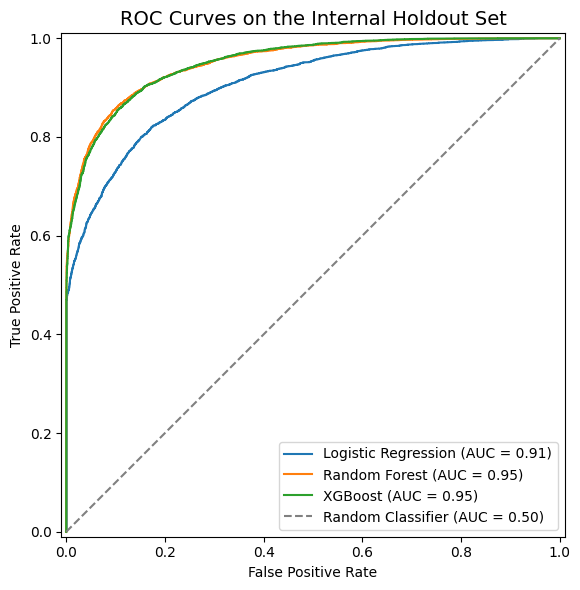

=== Holdout AUC scores ===
Random Forest: 0.9520
XGBoost: 0.9516
Logistic Regression: 0.9073

--- Classification report: Logistic Regression ---
                 precision    recall  f1-score   support

Not Dropped (0)       0.82      0.91      0.86      7433
    Dropped (1)       0.85      0.72      0.78      5260

       accuracy                           0.83     12693
      macro avg       0.83      0.81      0.82     12693
   weighted avg       0.83      0.83      0.83     12693


--- Classification report: Random Forest ---
                 precision    recall  f1-score   support

Not Dropped (0)       0.87      0.95      0.90      7433
    Dropped (1)       0.91      0.79      0.85      5260

       accuracy                           0.88     12693
      macro avg       0.89      0.87      0.88     12693
   weighted avg       0.88      0.88      0.88     12693


--- Classification report: XGBoost ---
                 precision    recall  f1-score   support

Not Dropped (0)      

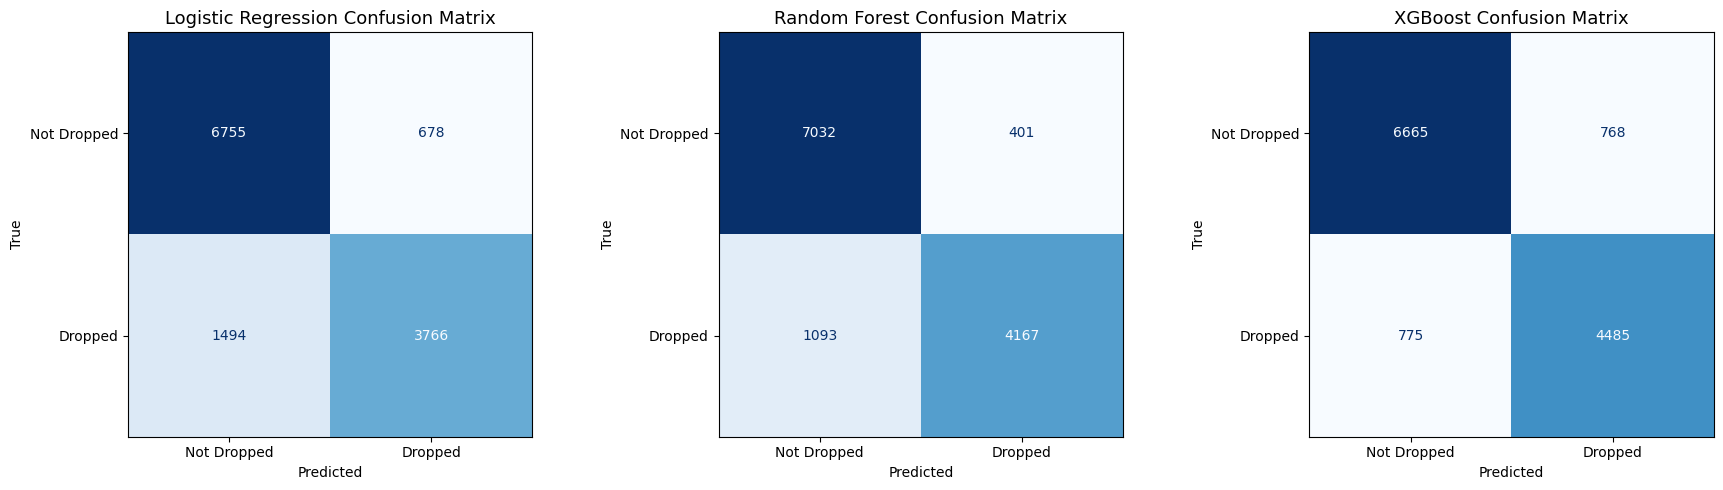

In [ ]:
# ==============================================================================
# Evaluate all three trained models on the internal holdout set.
# The holdout was not used during training. We report ROC-AUC,
# ROC curves, classification metrics and confusion matrices.
# ==============================================================================

# Process the holdout and separate its true labels
X_val_scaled = process_new_data(test_data)
y_val = test_data['Dropped_Course'].loc[X_val_scaled.index]

models = {
    'Logistic Regression': grid_log_reg.best_estimator_,
    'Random Forest': grid_rf.best_estimator_,
    'XGBoost': grid_xgb.best_estimator_
}

# ------------------------------------------------------------------------------
# ROC curves and AUC scores
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
auc_scores = {}

for name, model in models.items():
    # Probability of the positive class: Dropped = 1
    y_proba = model.predict_proba(X_val_scaled)[:, 1]

    # Calculate and store the AUC score
    auc_scores[name] = roc_auc_score(y_val, y_proba)

    # RocCurveDisplay adds the AUC automatically to the legend
    RocCurveDisplay.from_predictions(
        y_val,
        y_proba,
        name=name,
        ax=ax
    )

# Random-classifier reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier (AUC = 0.50)'
)

ax.set_title("ROC Curves on the Internal Holdout Set", fontsize=14)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# Display the exact AUC values with four digits after the decimal point
print("=== Holdout AUC scores ===")
for name, score in sorted(
    auc_scores.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {score:.4f}")

# ------------------------------------------------------------------------------
# Classification reports and confusion matrices
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_val_scaled)

    print(f"\n--- Classification report: {name} ---")
    print(
        classification_report(
            y_val,
            y_pred,
            target_names=['Not Dropped (0)', 'Dropped (1)']
        )
    )

    cm = confusion_matrix(y_val, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Not Dropped', 'Dropped']
    )
    disp.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False
    )

    ax.set_title(f"{name} Confusion Matrix", fontsize=13)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.show()

SHAP Global Feature Importance (bar):


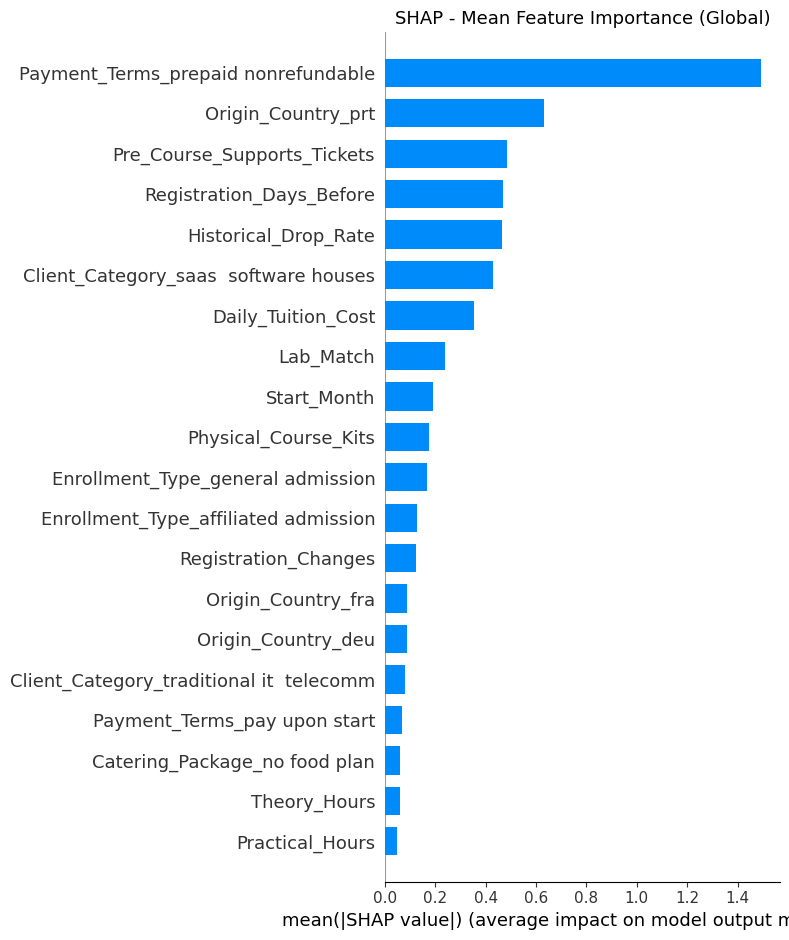

SHAP Summary (beeswarm) - direction of each feature's effect:


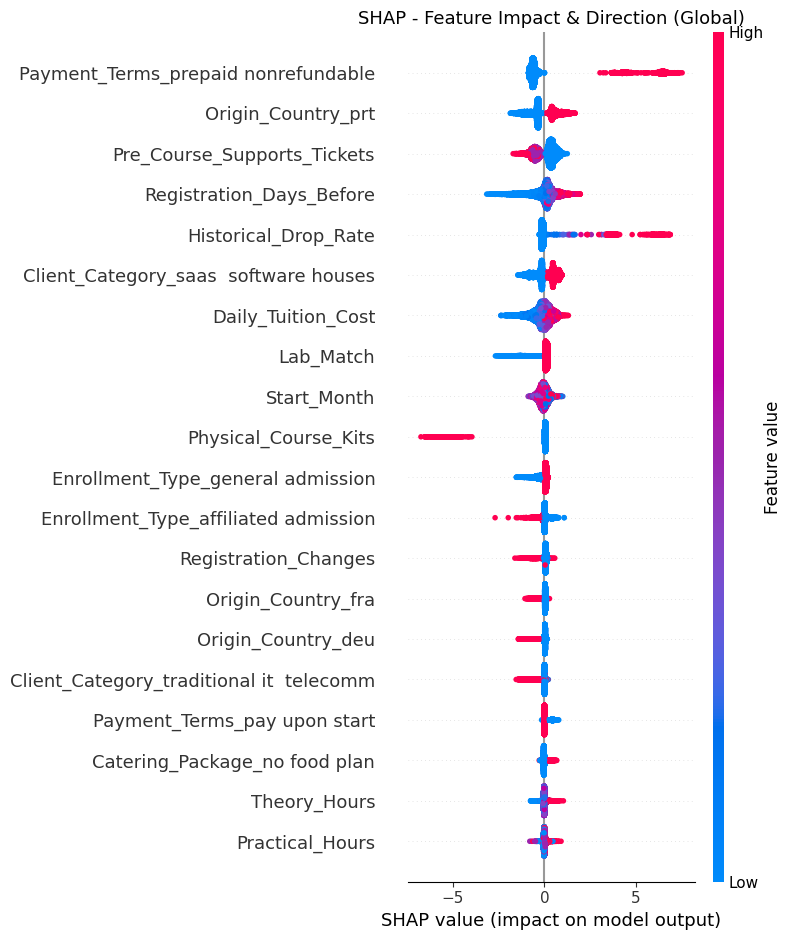

SHAP Local Explanation (Waterfall) - single prediction breakdown:


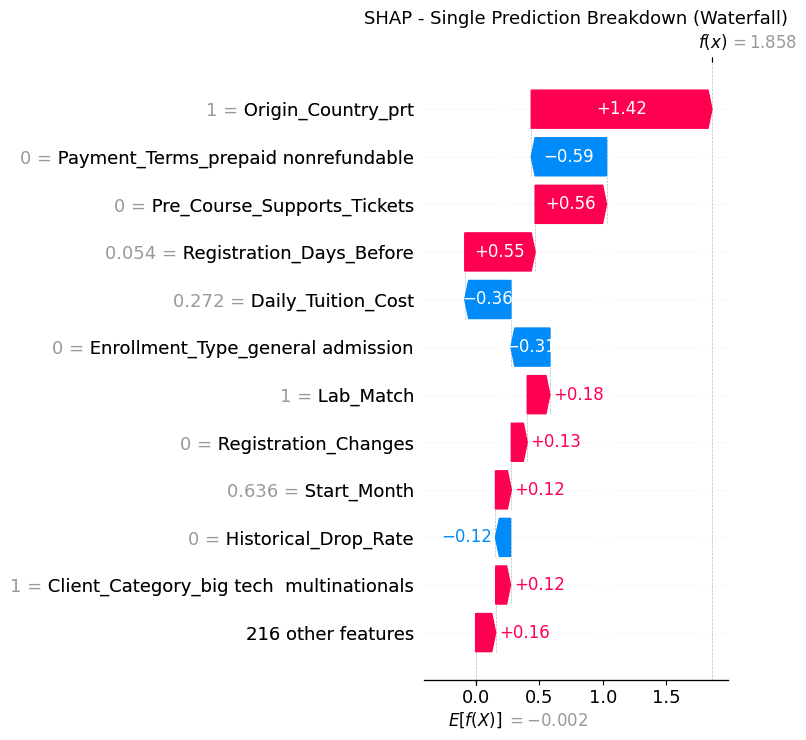

In [ ]:
# ==============================================================================
# SHAP analysis — interpreting WHY the chosen model (XGBoost) makes its predictions.
# SHAP assigns each feature a contribution to each prediction, giving both a global
# view (which features matter most overall) and a local view (how one specific
# prediction was built). This satisfies the project's requirement to explain the
# model's decision-making beyond raw metrics.
# ==============================================================================


# Build the explainer for the selected tree model (XGBoost)
# Select XGBoost as the final model for interpretation
best_model_name = 'XGBoost'
best_model = models[best_model_name]
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_val_scaled)

# --- Global view 1: mean feature importance (bar) — clearest for the report ---
print("SHAP Global Feature Importance (bar):")
shap.summary_plot(shap_values, X_val_scaled, plot_type="bar", show=False)
plt.title("SHAP - Mean Feature Importance (Global)", fontsize=13)
plt.tight_layout()
plt.savefig("shap_importance_bar.png", dpi=150, bbox_inches='tight')
plt.show()

# --- Global view 2: beeswarm (dot) — shows direction of each feature's effect ---
# Red = high feature value, Blue = low. Right of center = pushes toward "Dropped".
print("SHAP Summary (beeswarm) - direction of each feature's effect:")
shap.summary_plot(shap_values, X_val_scaled, plot_type="dot", show=False)
plt.title("SHAP - Feature Impact & Direction (Global)", fontsize=13)
plt.tight_layout()
plt.savefig("shap_summary_dot.png", dpi=150, bbox_inches='tight')
plt.show()

# --- Local view: explain a single prediction with a waterfall plot (clearer) ---
# Shows how one prediction is built step by step, from the base value up to the
# final output, each feature pushing the result toward "Dropped" (red) or "Stay" (blue).
print("SHAP Local Explanation (Waterfall) - single prediction breakdown:")

i = 0  # first observation in the holdout
single_explanation = shap.Explanation(
    values=shap_values[i],
    base_values=explainer.expected_value,
    data=X_val_scaled.iloc[i],
    feature_names=X_val_scaled.columns.tolist()
)

shap.plots.waterfall(single_explanation, max_display=12, show=False)
plt.title("SHAP - Single Prediction Breakdown (Waterfall)", fontsize=13)
plt.tight_layout()
plt.savefig("shap_waterfall_single.png", dpi=150, bbox_inches='tight')
plt.show()

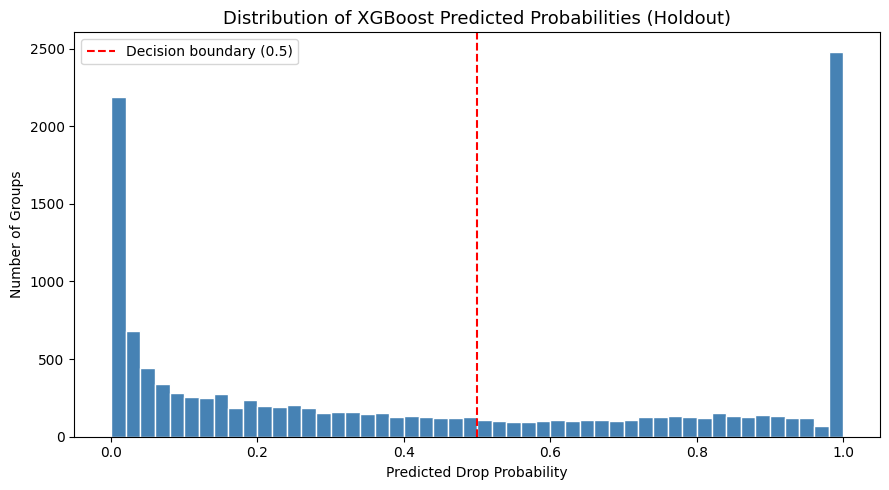

High-confidence predictions (<=0.2 or >=0.8): 8736 (68.8%)
Uncertain predictions (0.4-0.6 'grey zone'):  1129 (8.9%)

Accuracy on high-confidence predictions: 96.4%
Accuracy on uncertain predictions:       55.9%


In [ ]:
# ==============================================================================
# Deep-dive: model confidence analysis. We inspect the probability distribution
# XGBoost produces on the holdout to find WHERE it is confident vs. uncertain.
# Predictions near 0 or 1 are high-confidence; those near 0.5 are the model's
# "grey zone". We then check accuracy within each confidence band.
# ==============================================================================
y_proba_xgb = best_model.predict_proba(X_val_scaled)[:, 1]

# --- Distribution of predicted probabilities ---
plt.figure(figsize=(9, 5))
plt.hist(y_proba_xgb, bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.5, color='red', linestyle='--', label='Decision boundary (0.5)')
plt.title("Distribution of XGBoost Predicted Probabilities (Holdout)", fontsize=13)
plt.xlabel("Predicted Drop Probability")
plt.ylabel("Number of Groups")
plt.legend()
plt.tight_layout()
plt.show()

# --- Confidence bands: how many predictions are confident vs. uncertain ---
confident = ((y_proba_xgb <= 0.2) | (y_proba_xgb >= 0.8)).sum()
uncertain = ((y_proba_xgb > 0.4) & (y_proba_xgb < 0.6)).sum()
total = len(y_proba_xgb)
print(f"High-confidence predictions (<=0.2 or >=0.8): {confident} ({confident/total*100:.1f}%)")
print(f"Uncertain predictions (0.4-0.6 'grey zone'):  {uncertain} ({uncertain/total*100:.1f}%)")

# --- Is the model actually more accurate when it's confident? ---
y_pred_xgb = (y_proba_xgb >= 0.5).astype(int)
correct = (y_pred_xgb == y_val.values)

conf_mask = (y_proba_xgb <= 0.2) | (y_proba_xgb >= 0.8)
uncert_mask = (y_proba_xgb > 0.4) & (y_proba_xgb < 0.6)
print(f"\nAccuracy on high-confidence predictions: {correct[conf_mask].mean()*100:.1f}%")
print(f"Accuracy on uncertain predictions:       {correct[uncert_mask].mean()*100:.1f}%")

In [ ]:
# ==============================================================================
# Final pipeline: predictions on the real test file and build the
# submission.
# ==============================================================================

# 1. Load the official test file
test_file = pd.read_csv("/content/Test_Data_No_Target.csv")
print(f"Test file loaded: {test_file.shape}")

# 2. Keep Client_ID for the submission BEFORE processing (cleaned the same way)
client_ids = test_file['Client_ID'].apply(clean_client_id)

# 3. Run the exact same pipeline used on train/holdout
X_test_final = process_new_data(test_file)

# 4. Predict drop PROBABILITY with the selected model (XGBoost)
drop_probabilities = best_model.predict_proba(X_test_final)[:, 1]

# 5. Build the submission with the exact required column names
submission = pd.DataFrame({
    'Client_ID': client_ids.values,
    'Drop_Probability': drop_probabilities
})

# 6. Save to the required filename
submission.to_csv("Group_60_Submission.csv", index=False)

print("Submission file created: Group_60_Submission.csv")
print(f"Shape: {submission.shape}")
display(submission.head())
print("\nProbability sanity check:")
print(submission['Drop_Probability'].describe())

Test file loaded: (15866, 28)
Submission file created: Group_60_Submission.csv
Shape: (15866, 2)


,Client_ID,Drop_Probability
0,62246,0.073922
1,43031,0.999798
2,26571,0.133489
3,77694,0.999803
4,22185,0.291160



Probability sanity check:
count    15866.000000
mean         0.445234
std          0.356176
min          0.000048
25%          0.124579
50%          0.335517
75%          0.820536
max          0.999925
Name: Drop_Probability, dtype: float64
